# Лабораторна робота №4

## Тема роботи

Розподілена обробка великих даних із використанням Apache Spark.

## Мета роботи

Освоїти Spark DataFrame, RDD, ліниві обчислення та розбиття даних; порівняти еквівалентний аналіз pandas і локального Spark без припущення про обов'язкове прискорення.

## Завдання

Виконати всі 10 завдань: підготувати Spark-середовище, дослідити й очистити CSV, виконати фільтрацію та три групування, RDD, lazy evaluation, порівняння pandas і експеримент із партиціями.

## Теоретичні відомості

Spark будує граф операцій. Transformation (`filter`, `select`, `groupBy/agg`, `repartition`, `RDD.map`, `RDD.filter`) описують нові дані. Action (`count`, `collect`, `reduce`) запускають виконання. `cache()` лише позначає план для збереження; потрібна action, щоб матеріалізувати кеш. `repartition()` викликає shuffle; агрегація за Country також може вимагати shuffle.

Локальний `local[4]` виконує Spark на одному комп'ютері з чотирма слотами задач. Це справжній механізм Spark, проте не багатовузловий кластер і не доказ горизонтального масштабування. Вісім партицій не створюють вісім доступних ядер. Вхідні партиції та `spark.sql.shuffle.partitions=8` — різні параметри. AQE вимкнено для контрольованого експерименту, щоб Spark не змінював кількість партицій автоматично.



## Використані технології та підготовка середовища

Python, pandas, NumPy, Matplotlib та засоби паралельності з модуля роботи. Встановлення: `python -m pip install -r requirements.txt`. Повні обчислення: `python -m lab04.main`. Notebook відтворює аналіз збереженого повного експерименту; worker-функції розміщені в імпортованих `.py`, а запуск пулів відбувається через CLI.

In [1]:
from pathlib import Path
import sys
import json
import inspect
import random
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

root = Path.cwd().resolve()
if not (root / "common").exists():
    root = root.parent
if not (root / "common").exists():
    raise RuntimeError("Відкрийте notebook у корені проєкту або каталозі лабораторної.")
sys.path.insert(0, str(root))
from lab04 import algorithms as a
from lab04.spark_environment import create_spark

result_dir = root / "lab04" / "results"


def read_json(name):
    return json.loads((result_dir / name).read_text(encoding="utf-8"))


meta = read_json("metadata.json")
timings = pd.read_csv(result_dir / "timings.csv")
raw = pd.read_csv(result_dir / "timings_raw.csv")
pd.set_option("display.max_columns", 16)
assert not meta.get("quick", False), "Для захисту потрібен повний запуск."

## 1. SparkSession

Фактичні параметри сесії та локальні ресурси.

In [2]:
display(read_json("spark_session.json"))
print(inspect.getsource(create_spark))

{'version': '4.0.3',
 'master': 'local[4]',
 'default_parallelism': 4,
 'local_cores': 4,
 'configuration': {'spark.app.name': 'OnlineRetailII-Lab04',
  'spark.sql.shuffle.partitions': '8',
  'spark.driver.host': '127.0.0.1',
  'spark.ui.enabled': 'false',
  'spark.sql.session.timeZone': 'UTC',
  'spark.driver.bindAddress': '127.0.0.1',
  'spark.sql.adaptive.enabled': 'false',
  'spark.master': 'local[4]'}}

def create_spark(cores: int = 4, java_home: Path | None = None) -> SparkSession:
    if cores < 1:
        raise ValueError("Кількість ядер має бути додатною.")
    configure_java(java_home)
    os.environ["PYSPARK_PYTHON"] = sys.executable
    os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
    os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")
    spark = (
        SparkSession.builder.appName("OnlineRetailII-Lab04")
        .master(f"local[{cores}]")
        .config("spark.driver.host", "127.0.0.1")
        .config("spark.driver.bindAddress", "127.0.0.1")
        .config("spark.ui.enabled", "false")
        .config("spark.ui.showConsoleProgress", "false")
        .config("spark.sql.shuffle.partitions", "8")
        .config("spark.sql.adaptive.enabled", "false")
        .config("spark.sql.session.timeZone", "UTC")
        .config("spark.python.worker.faulthandler.enabled", "true")
        .getOrCreate()
    )
    spark.sparkContext.setLogLevel("ERROR")
    return spark



## 2. Завантаження та дослідження

Spark самостійно читає CSV; схема до й після явних приведень.

In [3]:
display(read_json("profile.json"))
display(meta["prepared_schema"])
print(inspect.getsource(a.load_spark))

{'rows': 1067371,
 'columns': 8,
 'raw_schema': {'type': 'struct',
  'fields': [{'name': 'InvoiceNo',
    'type': 'string',
    'nullable': True,
    'metadata': {}},
   {'name': 'StockCode', 'type': 'string', 'nullable': True, 'metadata': {}},
   {'name': 'Description', 'type': 'string', 'nullable': True, 'metadata': {}},
   {'name': 'Quantity', 'type': 'string', 'nullable': True, 'metadata': {}},
   {'name': 'InvoiceDate', 'type': 'string', 'nullable': True, 'metadata': {}},
   {'name': 'UnitPrice', 'type': 'string', 'nullable': True, 'metadata': {}},
   {'name': 'CustomerID', 'type': 'string', 'nullable': True, 'metadata': {}},
   {'name': 'Country', 'type': 'string', 'nullable': True, 'metadata': {}}]},
 'initial_partitions': 1,
 'missing': {'InvoiceNo': 0,
  'StockCode': 0,
  'Description': 4382,
  'Quantity': 0,
  'InvoiceDate': 0,
  'UnitPrice': 0,
  'CustomerID': 243007,
  'Country': 0}}

{'type': 'struct',
 'fields': [{'name': 'InvoiceNo',
   'type': 'string',
   'nullable': True,
   'metadata': {}},
  {'name': 'StockCode', 'type': 'string', 'nullable': True, 'metadata': {}},
  {'name': 'Description', 'type': 'string', 'nullable': True, 'metadata': {}},
  {'name': 'Quantity', 'type': 'double', 'nullable': True, 'metadata': {}},
  {'name': 'InvoiceDate',
   'type': 'timestamp',
   'nullable': True,
   'metadata': {}},
  {'name': 'UnitPrice', 'type': 'double', 'nullable': True, 'metadata': {}},
  {'name': 'CustomerID', 'type': 'string', 'nullable': True, 'metadata': {}},
  {'name': 'Country', 'type': 'string', 'nullable': True, 'metadata': {}},
  {'name': 'Revenue', 'type': 'double', 'nullable': True, 'metadata': {}}]}

def load_spark(spark: SparkSession, path: Path, limit: int | None = None) -> DataFrame:
    frame = (
        spark.read.option("header", True)
        .option("encoding", "UTF-8")
        .option("multiLine", True)
        .option("quote", '"')
        .option("escape", '"')
        .option("mode", "FAILFAST")
        .csv(str(path.resolve()))
    )
    for old, new in ALIASES.items():
        if old in frame.columns:
            if new in frame.columns:
                raise ValueError(f"Неоднозначний стовпець {new}")
            frame = frame.withColumnRenamed(old, new)
    if set(REQUIRED) - set(frame.columns):
        raise ValueError("CSV не містить усіх потрібних стовпців.")
    return frame.limit(limit) if limit else frame



## 3. Попередня обробка

Кількості виключень повинні збігатися з незалежною pandas-реалізацією.

In [4]:
cleaning = read_json("cleaning.json")
display(cleaning)
assert cleaning["spark"]["excluded"] == cleaning["pandas"]["excluded"]
print(inspect.getsource(a.prepare_spark))

{'spark': {'before': 1067371,
  'after': 1007913,
  'removed': 59458,
  'excluded': {'exact_duplicates': 34335,
   'cancelled': 19104,
   'missing_required': 4275,
   'invalid_quantity': 760,
   'invalid_price': 984,
   'invalid_revenue': 0}},
 'pandas': {'before': 1067371,
  'excluded': {'exact_duplicates': 34335,
   'cancelled': 19104,
   'missing_required': 4275,
   'invalid_quantity': 760,
   'invalid_price': 984,
   'invalid_revenue': 0},
  'diagnostics': {'cancelled': 19494,
   'nonpositive_quantity': 22950,
   'nonpositive_price': 6207,
   'missing_customers': 243007,
   'numeric_description': {'Quantity': {'count': 1067371.0,
     'mean': 9.9388984711033,
     'std': 172.70579407675342,
     'min': -80995.0,
     '25%': 1.0,
     '50%': 3.0,
     '75%': 10.0,
     'max': 80995.0},
    'UnitPrice': {'count': 1067371.0,
     'mean': 4.649387727416239,
     'std': 123.5530587214632,
     'min': -53594.36,
     '25%': 1.25,
     '50%': 2.1,
     '75%': 4.15,
     'max': 38970.0}}},

def prepare_spark(source: DataFrame) -> tuple[DataFrame, dict[str, Any]]:
    before = source.count()
    frame = source.dropDuplicates()
    remaining = frame.count()
    excluded = {"exact_duplicates": before - remaining}
    for name in ("InvoiceNo", "StockCode", "Description", "Country"):
        frame = frame.withColumn(
            name, F.when(F.length(F.trim(F.col(name))) > 0, F.trim(F.col(name)))
        )
    frame = frame.withColumn(
        "InvoiceDate", F.try_to_timestamp("InvoiceDate", F.lit("yyyy-MM-dd HH:mm:ss"))
    )
    for name in ("Quantity", "UnitPrice", "CustomerID"):
        frame = frame.withColumn(name, F.col(name).try_cast("double"))
    customer = F.col("CustomerID")
    frame = frame.withColumn(
        "CustomerID",
        F.when(
            finite("CustomerID") & (customer > 0) & (customer == F.floor(customer)),
            customer.try_cast("bigint").cast("string"),
        ),
    )
    required = [name for name in REQUIRED if name != "CustomerID"]
  

## 4. Фільтрація та вибірка

Revenue вище глобального середнього; справжні результати Spark.

In [5]:
display(read_json("filter.json"))
display(pd.read_csv(result_dir / "filtered_sample.csv"))

{'count': 191092, 'total': 13540604.94999984, 'threshold': 20.315503865909058}

,InvoiceNo,StockCode,CustomerID,Country,Revenue
0,489434,79323W,13085,United Kingdom,81.0
1,489434,22064,13085,United Kingdom,39.6
2,489434,21523,13085,United Kingdom,59.5
3,489438,21252,18102,United Kingdom,50.7
4,489438,21410,18102,United Kingdom,80.0
5,489438,84031A,18102,United Kingdom,168.0
6,489438,85183A,18102,United Kingdom,144.0
7,489439,POST,12682,France,54.0
8,489440,22349,18087,United Kingdom,30.0
9,489446,21733,13758,United Kingdom,81.6


## 5. GroupBy та агрегати

Усі країни, товари та відомі клієнти порівняно з pandas.

In [6]:
print(inspect.getsource(a.group_sales))
for name in ["countries", "products", "customers"]:
    table = pd.read_csv(result_dir / f"{name}.csv")
    display(Markdown(f"**{name}: {len(table)} груп**"))
    display(table.sort_values("total", ascending=False).head(10))

def group_sales(frame: DataFrame, key: str = "Country") -> DataFrame:
    return frame.groupBy(key).agg(
        F.count("*").alias("count"),
        F.sum("Revenue").alias("total"),
        F.avg("Revenue").alias("mean"),
    )



**countries: 43 груп**

,Country,count,total,mean
40,United Kingdom,926038,1.741020e+07,18.800736
11,EIRE,17154,6.587673e+05,38.403131
26,Netherlands,5085,5.540381e+05,108.955377
15,Germany,16432,4.250197e+05,25.865367
14,France,13639,3.504561e+05,25.695146
0,Australia,1789,1.692835e+05,94.624628
34,Spain,3662,1.083325e+05,29.582875
36,Switzerland,3122,1.006856e+05,32.250349
35,Sweden,1336,9.186982e+04,68.764835
10,Denmark,778,6.858069e+04,88.149987


**products: 4916 груп**

,StockCode,count,total,mean
4901,M,846,339226.24,400.976643
1638,22423,3950,330590.32,83.693752
4900,DOT,1415,309854.11,218.978170
4300,85123A,5511,257724.71,46.765507
4272,85099B,4042,180569.34,44.673266
2798,23843,1,168469.60,168469.600000
3147,47566,2705,148318.28,54.831157
3990,84879,2848,129324.49,45.408880
4903,POST,1851,125682.42,67.899741
1326,22086,2068,117760.29,56.944047


**customers: 5878 груп**

,CustomerID,count,total,mean
5692,18102,1040,580987.04,558.641385
2277,14646,3849,528602.52,137.335027
1789,14156,4038,313437.62,77.621996
2538,14911,11077,291420.81,26.308640
5050,17450,420,244784.25,582.819643
1331,13694,1519,195640.69,128.795714
5109,17511,1868,172132.87,92.148217
4061,16446,3,168472.50,56157.500000
4295,16684,718,147142.77,204.934220
68,12415,926,144458.37,156.002559


## 6. Механізм partitions

Вхідні партиції досліджуються при фіксованих local cores та shuffle partitions.

In [7]:
display(
    {
        "source_partitions": read_json("profile.json")["initial_partitions"],
        "prepared_partitions": meta["prepared_partitions"],
        "tested": meta["partition_values"],
        "cores": meta["spark"]["local_cores"],
    }
)

{'source_partitions': 1,
 'prepared_partitions': 8,
 'tested': [1, 2, 4, 8],
 'cores': 4}

## 7. RDD map, filter, reduce

Оброблено увесь очищений DataFrame, числовий результат перевірено.

In [8]:
print(inspect.getsource(a.rdd_demo))
display(read_json("rdd.json"))
assert read_json("rdd.json")["verified"]

def rdd_demo(frame: DataFrame, threshold: float) -> dict[str, float | int]:
    # Увесь очищений набір: map формує Revenue, filter використовує той самий поріг.
    mapped = frame.select("Quantity", "UnitPrice").rdd.map(
        lambda row: float(row[0]) * float(row[1])
    )
    filtered = mapped.filter(lambda revenue: revenue > threshold)
    count = filtered.count()
    total = filtered.reduce(operator.add) if count else 0.0
    expected = (
        frame.filter(F.col("Revenue") > threshold)
        .agg(F.count("*").alias("count"), F.sum("Revenue").alias("total"))
        .first()
    )
    assert count == expected["count"]
    assert math.isclose(total, expected["total"] or 0.0, rel_tol=1e-9, abs_tol=1e-7)
    return {"count": count, "total": total, "threshold": threshold}



{'count': 191092,
 'total': 13540604.94999984,
 'threshold': 20.315503865909058,
 'seconds': 15.030052199996135,
 'verified': True}

## 8. Transformation, Action та lazy evaluation

Фактичні Spark job до/після побудови плану та collect.

In [9]:
lazy = read_json("lazy_evaluation.json")
display(lazy)
assert lazy["jobs_before"] == lazy["jobs_after_transformation"]
assert len(lazy["jobs_after_collect"]) > len(lazy["jobs_after_transformation"])
print((result_dir / "query_plan.txt").read_text(encoding="utf-8"))

{'jobs_before': [],
 'jobs_after_transformation': [],
 'jobs_after_collect': [20],
 'transformations': ['filter',
  'select',
  'groupBy/agg',
  'repartition',
  'RDD.map',
  'RDD.filter'],
 'actions': ['count', 'collect', 'RDD.reduce']}

== Parsed Logical Plan ==
'Aggregate ['Country], ['Country, 'count(*) AS count#4457, 'sum('Revenue) AS total#4458, 'avg('Revenue) AS mean#4459]
+- Filter (Revenue#2165 > 20.315503865909058)
   +- Filter ((isnotnull(Revenue#2165) AND NOT isnan(Revenue#2165)) AND NOT (abs(Revenue#2165) = Infinity))
      +- Project [InvoiceNo#1308, StockCode#1309, Description#1310, Quantity#1313, InvoiceDate#1312, UnitPrice#1314, CustomerID#1316, Country#1311, (Quantity#1313 * UnitPrice#1314) AS Revenue#2165]
         +- Filter NOT (NOT ((isnotnull(UnitPrice#1314) AND NOT isnan(UnitPrice#1314)) AND NOT (abs(UnitPrice#1314) = Infinity)) OR (UnitPrice#1314 <= cast(0 as double)))
            +- Filter NOT (NOT ((isnotnull(Quantity#1313) AND NOT isnan(Quantity#1313)) AND NOT (abs(Quantity#1313) = Infinity)) OR (Quantity#1313 <= cast(0 as double)))
               +- Filter NOT (((((((false OR isnull(InvoiceNo#1308)) OR isnull(StockCode#1309)) OR isnull(Description#1310)) OR isnull(Quantity#1313)) OR isnull(In

## 9. Pandas проти PySpark

Однакові очищені дані та count/sum/mean за Country; прогріті рушії.

,workload,method,workers,effective_workers,repeat,seconds,verified
0,engines,sequential,1,1,1,0.124872,True
1,engines,spark,4,4,1,0.208247,True
2,engines,sequential,1,1,2,0.130255,True
3,engines,spark,4,4,2,0.205235,True
4,engines,sequential,1,1,3,0.113583,True
5,engines,spark,4,4,3,0.244719,True


,workload,method,workers,effective_workers,seconds,min_seconds,max_seconds,verified,repeats,speedup,efficiency_pct
0,engines,sequential,1,1,0.124872,0.113583,0.130255,True,3,1.000000,100.000000
1,engines,spark,4,4,0.208247,0.205235,0.244719,True,3,0.599633,14.990821


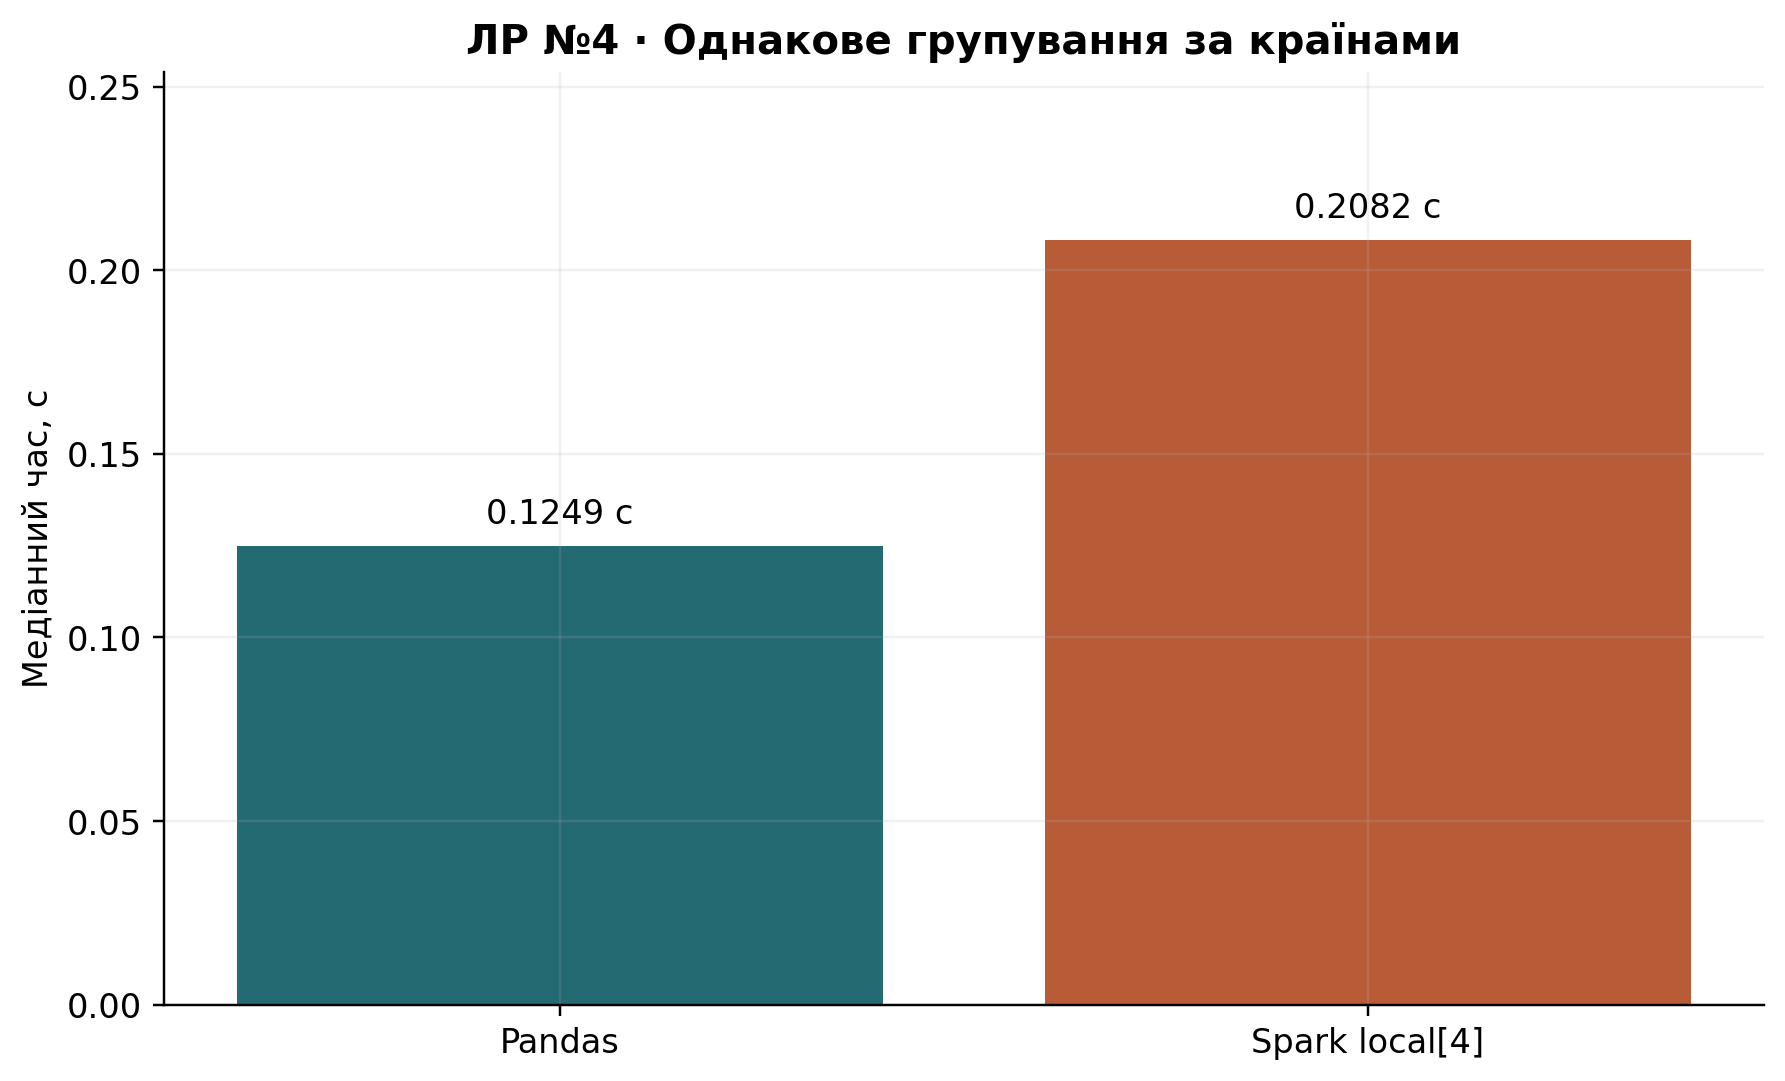

In [10]:
display(raw)
display(timings)
display(Image(filename=str(result_dir / "engines.png")))

## 10. Експеримент з partitions

Три повтори з repartition у таймері та без нього.

,scope,partitions,repeat,seconds,verified,materialization_seconds
0,with_repartition,1,1,0.441738,True,NaN
1,with_repartition,1,2,0.355414,True,NaN
2,with_repartition,1,3,0.349226,True,NaN
3,cached_partitions,1,1,0.157261,True,2.820560
4,cached_partitions,1,2,0.139795,True,2.820560
5,cached_partitions,1,3,0.203634,True,2.820560
6,with_repartition,2,1,0.438370,True,NaN
7,with_repartition,2,2,0.427184,True,NaN
8,with_repartition,2,3,0.462771,True,NaN
9,cached_partitions,2,1,0.132861,True,2.129017


,scope,partitions,seconds,min_seconds,max_seconds,repeats,verified
0,cached_partitions,1,0.157261,0.139795,0.203634,3,True
1,cached_partitions,2,0.160572,0.132861,0.164094,3,True
2,cached_partitions,4,0.142212,0.121166,0.158419,3,True
3,cached_partitions,8,0.175679,0.155447,0.185674,3,True
4,with_repartition,1,0.355414,0.349226,0.441738,3,True
5,with_repartition,2,0.438370,0.427184,0.462771,3,True
6,with_repartition,4,0.354684,0.351454,0.376803,3,True
7,with_repartition,8,0.473515,0.432736,0.504695,3,True


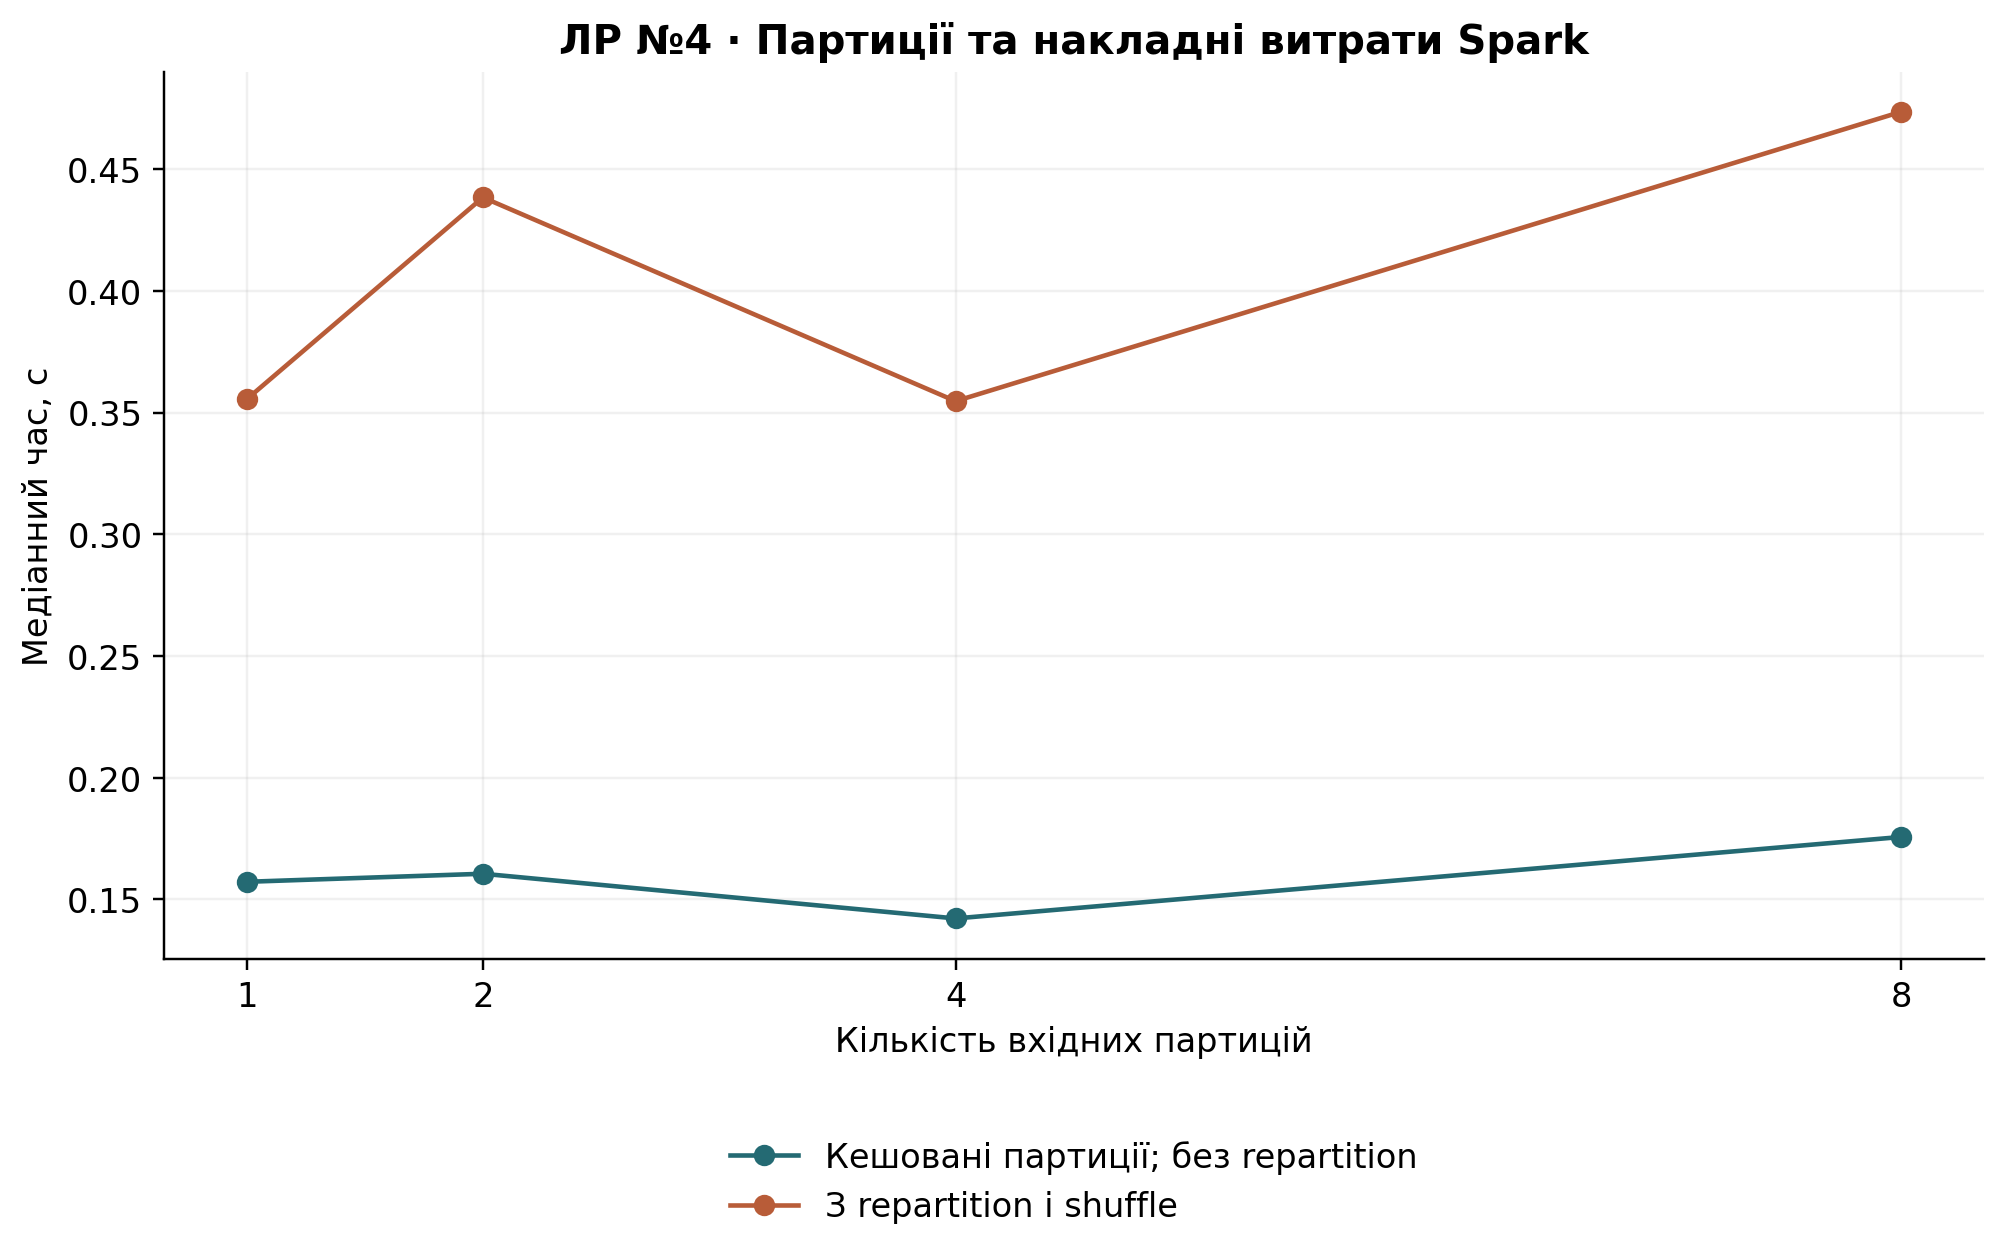

In [11]:
partition_raw = pd.read_csv(result_dir / "partitions_raw.csv")
display(partition_raw)
display(pd.read_csv(result_dir / "partitions.csv"))
assert partition_raw.verified.all()
display(Image(filename=str(result_dir / "partitions.png")))

## Аналіз результатів

Spark 4.0.3, local[4]; 1,067,371 вихідних і 1,007,913 очищених рядків. Початкових партицій: 1; після очищення: 8. Кількості виключених рядків Spark та pandas збіглися для кожної причини.

| Причина          |   Виключено |
|:-----------------|------------:|
| exact_duplicates |       34335 |
| cancelled        |       19104 |
| missing_required |        4275 |
| invalid_quantity |         760 |
| invalid_price    |         984 |
| invalid_revenue  |           0 |

Окремі етапи (не входять у прогріті заміри):

| Етап                          |   Час, с |
|:------------------------------|---------:|
| spark_startup_seconds         |   6.0633 |
| spark_load_seconds            |   5.5770 |
| spark_prepare_seconds         |  30.1726 |
| cache_materialization_seconds |   5.6816 |
| pandas_load_seconds           |   1.9689 |
| pandas_prepare_seconds        |   4.9557 |

### Партиції: два різні інтервали вимірювання

| scope             |   partitions |   seconds |   min_seconds |   max_seconds |   repeats | verified   |
|:------------------|-------------:|----------:|--------------:|--------------:|----------:|:-----------|
| cached_partitions |            1 |    0.1573 |        0.1398 |        0.2036 |         3 | True       |
| cached_partitions |            2 |    0.1606 |        0.1329 |        0.1641 |         3 | True       |
| cached_partitions |            4 |    0.1422 |        0.1212 |        0.1584 |         3 | True       |
| cached_partitions |            8 |    0.1757 |        0.1554 |        0.1857 |         3 | True       |
| with_repartition  |            1 |    0.3554 |        0.3492 |        0.4417 |         3 | True       |
| with_repartition  |            2 |    0.4384 |        0.4272 |        0.4628 |         3 | True       |
| with_repartition  |            4 |    0.3547 |        0.3515 |        0.3768 |         3 | True       |
| with_repartition  |            8 |    0.4735 |        0.4327 |        0.5047 |         3 | True       |

Еквівалентне групування: pandas 0.1249 с; Spark 0.2082 с; S=0.5996. Локальний Spark повільніший за pandas у цьому вимірюванні. Набір приблизно 95 MB вміщується в пам'ять, а групування має лише кілька десятків країн. Планування Spark job, shuffle та передавання підсумку через JVM/Python можуть переважати над обчисленнями. Це не заперечує переваг Spark для даних іншого масштабу або кластера.

cached_partitions: найменша медіана при 4 партиціях, 0.1422 с.

with_repartition: найменша медіана при 4 партиціях, 0.3547 с.

Різниця між сценаріями показує вплив перерозподілу та матеріалізації. Вимірювання з repartition починається з кешованого очищеного набору; варіант cached_partitions додатково кешує новий розподіл. Це різні межі та стани кешу, тому їх різницю не слід видавати за точну ізольовану вартість shuffle. Після певного p додаткові партиції створюють більше дрібних задач при незмінних чотирьох слотах. Вихідна кількість партицій залежить від способу читання: multiLine обробляє цей CSV як один файл. Далі dropDuplicates і groupBy використовують shuffle. Висновок стосується локального виконання, трьох повторів та зафіксованих налаштувань; оптимум може змінитися на іншій машині. Справжні Spark DataFrame і Python RDD дали еквівалентні результати; перевірені всі країни, товари та відомі клієнти.

In [12]:
display(timings)

,workload,method,workers,effective_workers,seconds,min_seconds,max_seconds,verified,repeats,speedup,efficiency_pct
0,engines,sequential,1,1,0.124872,0.113583,0.130255,True,3,1.000000,100.000000
1,engines,spark,4,4,0.208247,0.205235,0.244719,True,3,0.599633,14.990821


## Висновки

Для прогрітого локального Spark S=0.5996 відносно pandas. Усі DataFrame/RDD та групування перевірені. Зміна партицій впливає на планування та shuffle; її слід оцінювати при явних межах вимірювання.